# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [2]:
%pip install torch torchvision torchaudio

Note: you may need to restart the kernel to use updated packages.


In [1]:
import os
import re
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from IPython.display import display


torch.manual_seed(42)
torch.set_num_threads(1)

## Step 2 — Upload the dataset

In [2]:
# The CSV can be placed alongside this notebook (Jupyter) or in /content (Colab).
paths = ["Lab_11_QnA_Dataset.csv", "/mnt/data/Lab_11_QnA_Dataset.csv", "/content/Lab_11_QnA_Dataset.csv"]
dataset_path = next((p for p in paths if os.path.exists(p)), None)
if dataset_path is None:
    raise FileNotFoundError("Place Lab_11_QnA_Dataset.csv in the notebook folder, then rerun.")
df = pd.read_csv(dataset_path)
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
# Preprocessing without TensorFlow: lowercase, remove punctuation, tokenize, and pad.
def tokenize(text):
    return re.findall(r"[a-z0-9]+", str(text).lower())

df["question"] = df["question"].astype(str).str.lower()
tokenized = [tokenize(q) for q in df["question"]]
vocab = {word: idx + 1 for idx, word in enumerate(sorted(set(w for q in tokenized for w in q)))}
max_length = max(map(len, tokenized))
sequences = [[vocab[w] for w in q] for q in tokenized]
X = torch.tensor([s + [0] * (max_length - len(s)) for s in sequences], dtype=torch.long)
classes = sorted(df["answer_id"].unique().tolist())
label_to_index = {label: i for i, label in enumerate(classes)}
y = torch.tensor([label_to_index[v] for v in df["answer_id"]], dtype=torch.long)
print("Vocabulary size:", len(vocab), "| Padded length:", max_length)

Vocabulary size: 225 | Padded length: 11


## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(vocab) + 1, 16, padding_idx=0)
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, len(classes))

    def forward(self, x):
        features, _ = self.rnn(self.emb(x))
        scores = self.att(features).squeeze(-1)
        scores = scores.masked_fill(x == 0, -1e9)  # Do not attend to padding.
        weights = torch.softmax(scores, dim=1)
        context = (features * weights.unsqueeze(-1)).sum(dim=1)
        return self.fc(context), weights

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
model.train()
for epoch in range(150):
    optimizer.zero_grad()  # Important: clear gradients at every iteration.
    logits, _ = model(X)
    loss = nn.functional.cross_entropy(logits, y)
    loss.backward()
    optimizer.step()
    if (epoch + 1) % 50 == 0:
        accuracy = (logits.argmax(dim=1) == y).float().mean().item()
        print(f"Epoch {epoch+1}: loss={loss.item():.4f}, training accuracy={accuracy:.1%}")
model.eval()
print("Training finished!")

Epoch 50: loss=0.0465, training accuracy=99.4%
Epoch 100: loss=0.0122, training accuracy=99.4%
Epoch 150: loss=0.0045, training accuracy=100.0%
Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

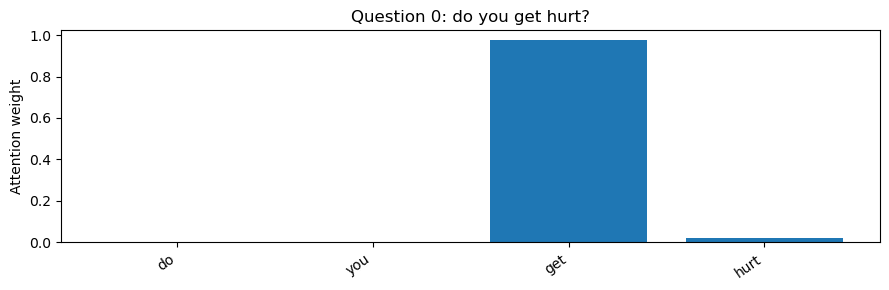

Highest-attention word: 'get' (weight 0.974); predicted answer ID: 0


In [6]:
# Visualize one question from the dataset.
def plot_attention(index, ax=None):
    words = tokenized[index]
    with torch.no_grad():
        logits, weights = model(X[index:index+1])
    scores = weights[0, :len(words)].cpu().tolist()
    if ax is None:
        _, ax = plt.subplots(figsize=(9, 3))
    ax.bar(range(len(words)), scores)
    ax.set_xticks(range(len(words)), words, rotation=35, ha="right")
    ax.set_title(f"Question {index}: {df.iloc[index]['question']}")
    ax.set_ylabel("Attention weight")
    top_index = max(range(len(words)), key=lambda j: scores[j])
    return words[top_index], scores[top_index], classes[logits.argmax(dim=1).item()]

word, weight, predicted = plot_attention(0)
plt.tight_layout()
plt.show()
print(f"Highest-attention word: '{word}' (weight {weight:.3f}); predicted answer ID: {predicted}")

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

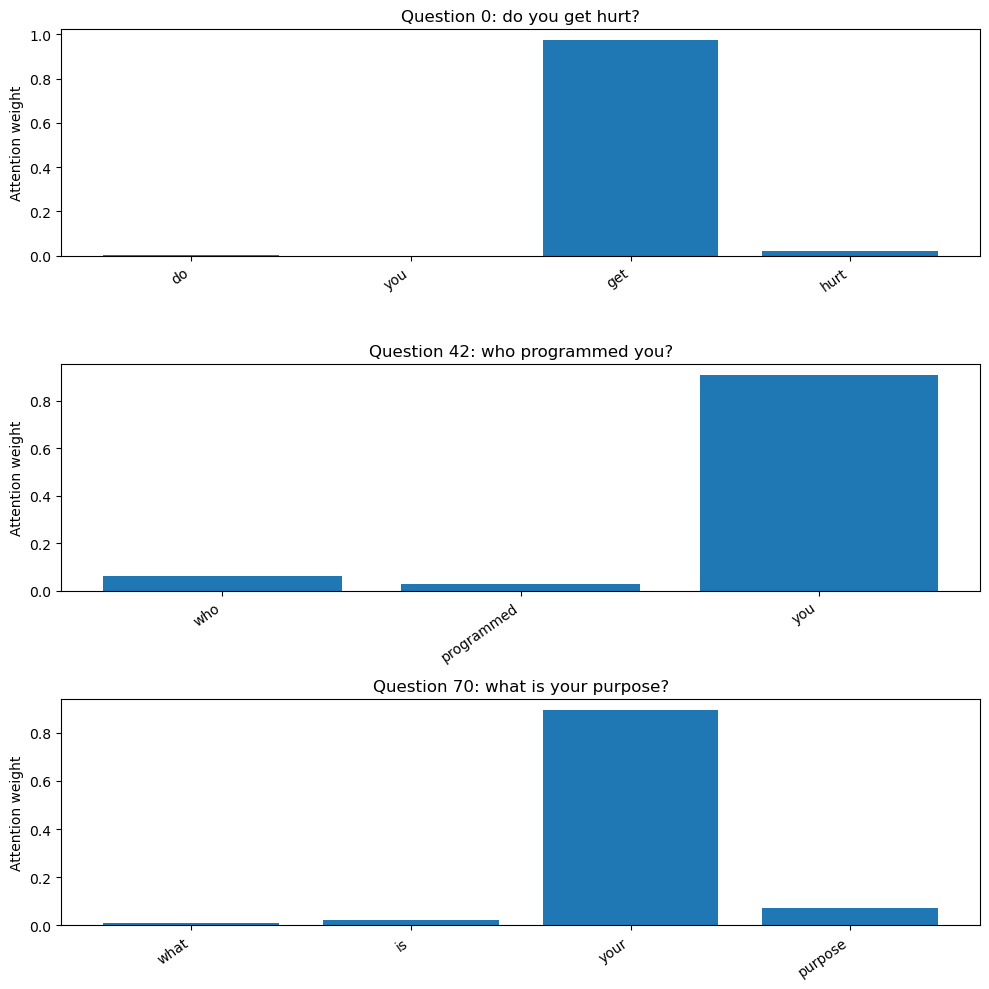

Question 0: do you get hurt?
  Highest attention: 'get' (0.974); predicted answer ID: 0
Question 42: who programmed you?
  Highest attention: 'you' (0.910); predicted answer ID: 3
Question 70: what is your purpose?
  Highest attention: 'your' (0.895); predicted answer ID: 5

Answer: High-weight words can be important clues to a question's meaning, especially when they describe its topic. However, the highest-weight word is not always the most meaningful word; the model learned weights to predict an answer class, not to provide a linguistic explanation.


In [7]:
# Task 1: Compare attention for three different questions.
selected_indices = [0, 42, 70]  # Physical abilities, creator, and purpose.
fig, axes = plt.subplots(3, 1, figsize=(10, 10))
results_task1 = []
for index, ax in zip(selected_indices, axes):
    top_word, top_weight, predicted = plot_attention(index, ax=ax)
    results_task1.append((index, df.iloc[index]["question"], top_word, top_weight, predicted))
plt.tight_layout()
plt.show()

for index, question, top_word, top_weight, predicted in results_task1:
    print(f"Question {index}: {question}")
    print(f"  Highest attention: '{top_word}' ({top_weight:.3f}); predicted answer ID: {predicted}")

# Observation: the model assigns higher weights to words that it finds useful
# for predicting the answer. The top word may be meaningful (e.g., 'hurt',
# 'programmed', or 'purpose'), but it may also be a common word. Attention
# weights show this model's learned focus, not guaranteed explanations.
print("\nAnswer: High-weight words can be important clues to a question's meaning, "
      "especially when they describe its topic. However, the highest-weight "
      "word is not always the most meaningful word; the model learned weights "
      "to predict an answer class, not to provide a linguistic explanation.")

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

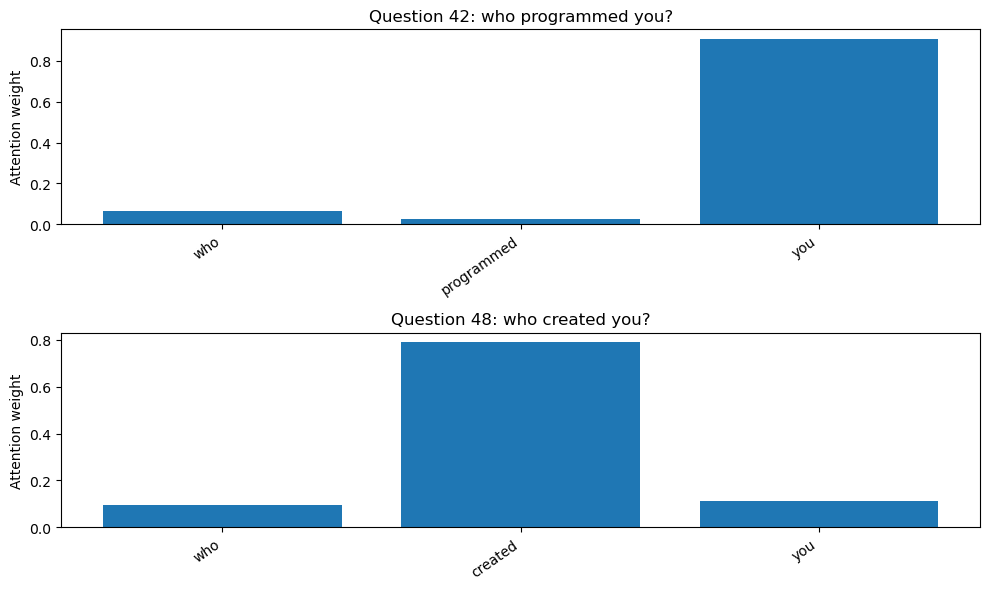

Question: who programmed you?
  Highest attention: 'you' (0.910); predicted answer ID: 3
Question: who created you?
  Highest attention: 'created' (0.791); predicted answer ID: 3

Answer: These questions both ask who made the assistant, but they use different verbs ('programmed' and 'created').
The model's highest-weight words are 'you' and 'created'. They differ in this run. This suggests that attention can emphasize different word-level clues for similar meanings. Comparable predictions are possible even when attention distributions differ; weights are not proof of reasoning.


In [8]:
# Task 2: Two similar questions with different wording (both answer ID 3).
similar_indices = [42, 48]  # 'Who programmed you?' vs 'Who created you?'
fig, axes = plt.subplots(2, 1, figsize=(10, 6))
results_task2 = []
for index, ax in zip(similar_indices, axes):
    top_word, top_weight, predicted = plot_attention(index, ax=ax)
    results_task2.append((df.iloc[index]["question"], top_word, top_weight, predicted))
plt.tight_layout()
plt.show()

for question, top_word, top_weight, predicted in results_task2:
    print(f"Question: {question}")
    print(f"  Highest attention: '{top_word}' ({top_weight:.3f}); predicted answer ID: {predicted}")

w1, w2 = results_task2[0][1], results_task2[1][1]
print("\nAnswer: These questions both ask who made the assistant, but they use "
      "different verbs ('programmed' and 'created').")
print(f"The model's highest-weight words are '{w1}' and '{w2}'. "
      + ("They match in this run. " if w1 == w2 else "They differ in this run. ")
      + "This suggests that attention can emphasize different word-level "
      "clues for similar meanings. Comparable predictions are possible even "
      "when attention distributions differ; weights are not proof of reasoning.")